In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving SUPER MARKET DATA - supermarket_sales_500_rows.csv to SUPER MARKET DATA - supermarket_sales_500_rows.csv


In [34]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 500
Columns: 13


In [4]:
df.head()

,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Invoice ID', 'Date', 'Branch', 'City', 'Customer Type', 'Gender', 'Product', 'Category', 'Quantity', 'Unit Price', 'Payment', 'Rating', 'Sales']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     500 non-null    object 
 1   Date           500 non-null    object 
 2   Branch         500 non-null    object 
 3   City           500 non-null    object 
 4   Customer Type  500 non-null    object 
 5   Gender         500 non-null    object 
 6   Product        500 non-null    object 
 7   Category       500 non-null    object 
 8   Quantity       500 non-null    int64  
 9   Unit Price     500 non-null    float64
 10  Payment        500 non-null    object 
 11  Rating         500 non-null    float64
 12  Sales          500 non-null    float64
dtypes: float64(3), int64(1), object(9)
memory usage: 50.9+ KB


In [7]:
df.describe(include="all")

,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
count,500,500,500,500,500,500,500,500,500.000000,500.000000,500,500.000000,500.000000
unique,500,173,4,4,2,2,20,8,NaN,NaN,4,NaN,NaN
top,INV0500,2026-01-12,C,Mumbai,Member,Female,Rice,Grocery,NaN,NaN,UPI,NaN,NaN
freq,1,10,143,143,296,255,29,82,NaN,NaN,127,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.536000,88.660700,NaN,3.994400,488.822160
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.875629,57.284029,NaN,0.574481,437.327833
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,27.670000,NaN,3.000000,28.610000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,43.955000,NaN,3.500000,189.212500
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.500000,61.880000,NaN,4.000000,335.910000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,128.567500,NaN,4.500000,609.885000


In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Invoice ID       0
Date             0
Branch           0
City             0
Customer Type    0
Gender           0
Product          0
Category         0
Quantity         0
Unit Price       0
Payment          0
Rating           0
Sales            0
dtype: int64


In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [10]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['invoice_id', 'date', 'branch', 'city', 'customer_type', 'gender', 'product', 'category', 'quantity', 'unit_price', 'payment', 'rating', 'sales']


In [11]:
df = df.drop_duplicates()

print("Duplicates removed.")
print("Remaining rows:", len(df))

Duplicates removed.
Remaining rows: 500


In [12]:
print(df.dtypes)

invoice_id        object
date              object
branch            object
city              object
customer_type     object
gender            object
product           object
category          object
quantity           int64
unit_price       float64
payment           object
rating           float64
sales            float64
dtype: object


In [13]:
possible_sales_columns = [
    "sales", "total_sales", "total",
    "revenue", "amount", "gross_income"
]

sales_col = next(
    (col for col in possible_sales_columns if col in df.columns),
    None
)

if sales_col:
    df[sales_col] = pd.to_numeric(df[sales_col], errors="coerce")

    print(f"Total Sales: ₹{df[sales_col].sum():,.2f}")
    print(f"Average Sales: ₹{df[sales_col].mean():,.2f}")
else:
    print("Sales column not found. Check your column names.")

Total Sales: ₹244,411.08
Average Sales: ₹488.82


In [14]:
product_col = next(
    (col for col in ["product", "product_name", "product_line"]
     if col in df.columns),
    None
)

if product_col and sales_col:
    product_sales = (
        df.groupby(product_col)[sales_col]
        .sum()
        .sort_values(ascending=False)
    )

    display(product_sales.to_frame("Total Sales"))
else:
    print("Product or sales column not found.")

,Total Sales
product,
Cheese,27906.30
Coffee,27694.87
Shampoo,27497.48
Cooking Oil,21525.06
Tea,17681.59
Apples,17057.41
Face Wash,11946.85
Rice,11754.17
Cold Drink,10731.78


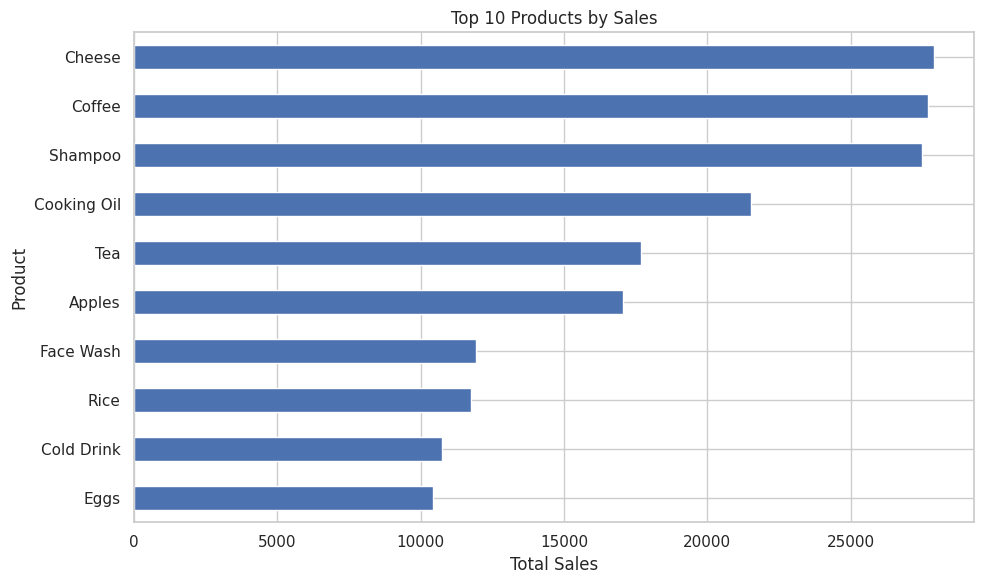

In [15]:
if product_col and sales_col:
    product_sales = product_sales.dropna().head(10)

    product_sales.sort_values().plot(
        kind="barh",
        figsize=(10, 6)
    )

    plt.title("Top 10 Products by Sales")
    plt.xlabel("Total Sales")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

,Total Sales
branch,
C,72469.45
B,64116.26
D,55468.29
A,52357.08


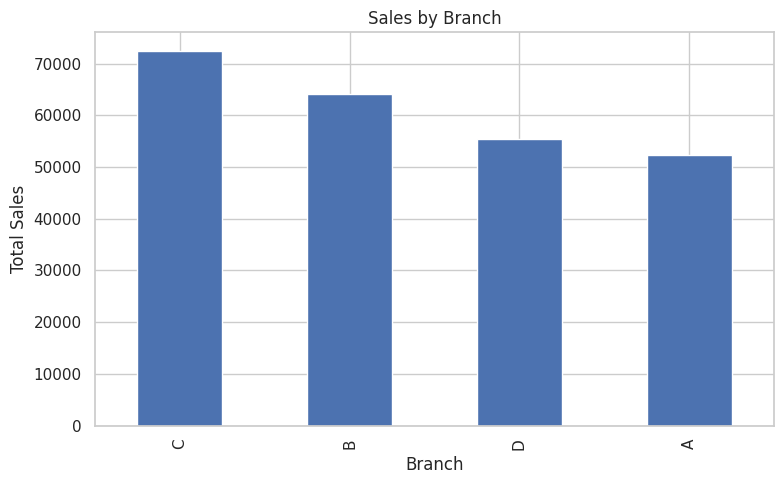

In [16]:
branch_col = next(
    (col for col in ["branch", "store", "store_id"]
     if col in df.columns),
    None
)

if branch_col and sales_col:
    branch_sales = (
        df.groupby(branch_col)[sales_col]
        .sum()
        .sort_values(ascending=False)
    )

    display(branch_sales.to_frame("Total Sales"))

    branch_sales.plot(kind="bar", figsize=(8, 5))
    plt.title("Sales by Branch")
    plt.xlabel("Branch")
    plt.ylabel("Total Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Branch or sales column not found.")

,Transaction Count
payment,
UPI,127
Net Banking,126
Card,125
Cash,122


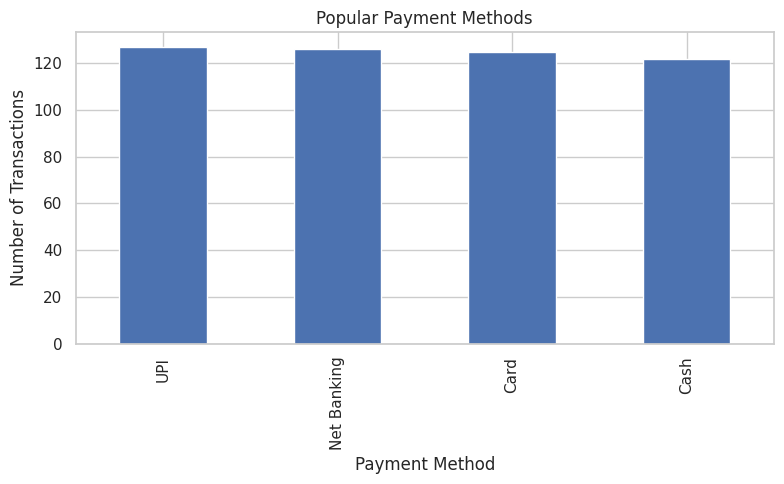

In [17]:
payment_col = next(
    (col for col in ["payment", "payment_method", "payment_type"]
     if col in df.columns),
    None
)

if payment_col:
    payment_counts = df[payment_col].value_counts()

    display(payment_counts.to_frame("Transaction Count"))

    payment_counts.plot(kind="bar", figsize=(8, 5))
    plt.title("Popular Payment Methods")
    plt.xlabel("Payment Method")
    plt.ylabel("Number of Transactions")
    plt.tight_layout()
    plt.show()
else:
    print("Payment column not found.")

Average Customer Rating: 3.99


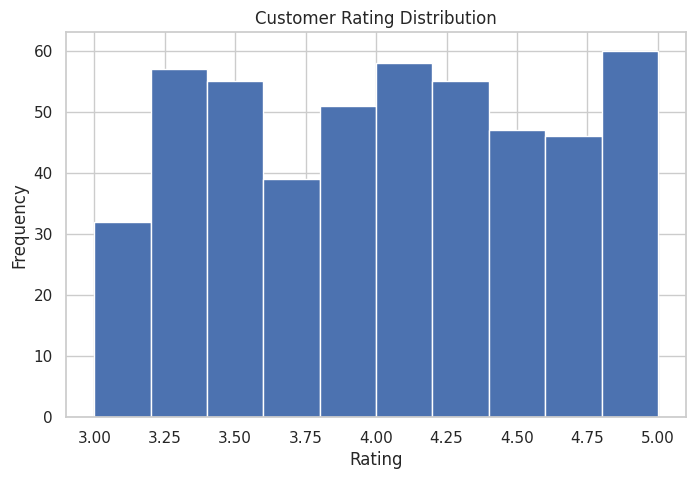

In [18]:
rating_col = next(
    (col for col in ["rating", "customer_rating", "review_rating"]
     if col in df.columns),
    None
)

if rating_col:
    df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")

    print(f"Average Customer Rating: {df[rating_col].mean():.2f}")

    df[rating_col].dropna().plot(
        kind="hist",
        bins=10,
        figsize=(8, 5)
    )

    plt.title("Customer Rating Distribution")
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    plt.show()
else:
    print("Rating column not found.")

In [19]:
customer_col = next(
    (col for col in ["customer_type", "customer", "membership"]
     if col in df.columns),
    None
)

if customer_col and sales_col:
    customer_analysis = df.groupby(customer_col)[sales_col].agg(
        ["count", "sum", "mean"]
    )

    customer_analysis.columns = [
        "Transaction Count",
        "Total Sales",
        "Average Sales"
    ]

    display(customer_analysis)
else:
    print("Customer type or sales column not found.")

,Transaction Count,Total Sales,Average Sales
customer_type,,,
Member,296,143009.30,483.139527
Normal,204,101401.78,497.067549


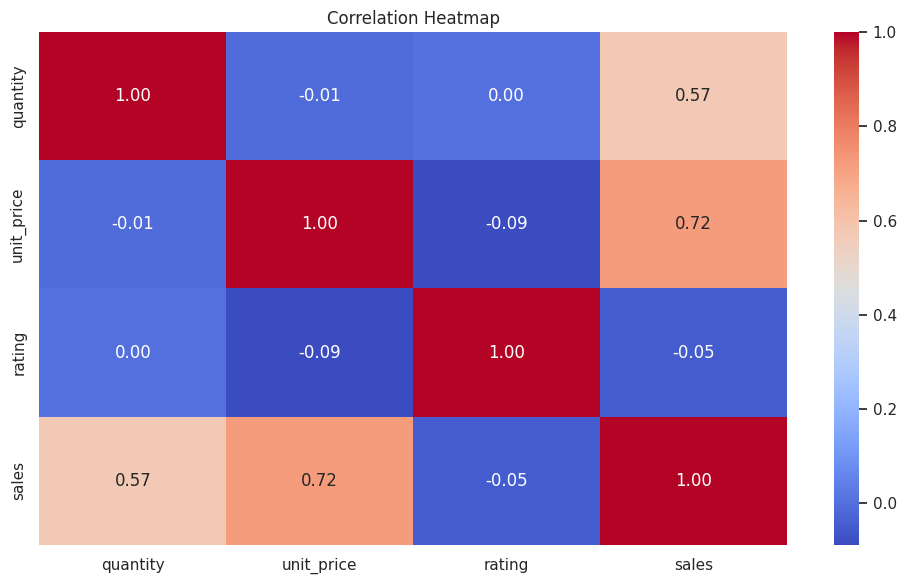

In [20]:
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")

In [21]:
df.to_csv("cleaned_supermarket_sales.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [22]:
from google.colab import files

files.download("cleaned_supermarket_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Supermarket Sales Summary

print("=" * 50)
print("       SUPERMARKET SALES ANALYSIS")
print("=" * 50)

print("Total Records:", len(df))

if sales_col is not None:
    print(f"Total Sales: ₹{df[sales_col].sum():,.2f}")
    print(f"Average Sales: ₹{df[sales_col].mean():,.2f}")
    print(f"Maximum Sales: ₹{df[sales_col].max():,.2f}")
    print(f"Minimum Sales: ₹{df[sales_col].min():,.2f}")

print("=" * 50)

       SUPERMARKET SALES ANALYSIS
Total Records: 500
Total Sales: ₹244,411.08
Average Sales: ₹488.82
Maximum Sales: ₹2,114.82
Minimum Sales: ₹28.61


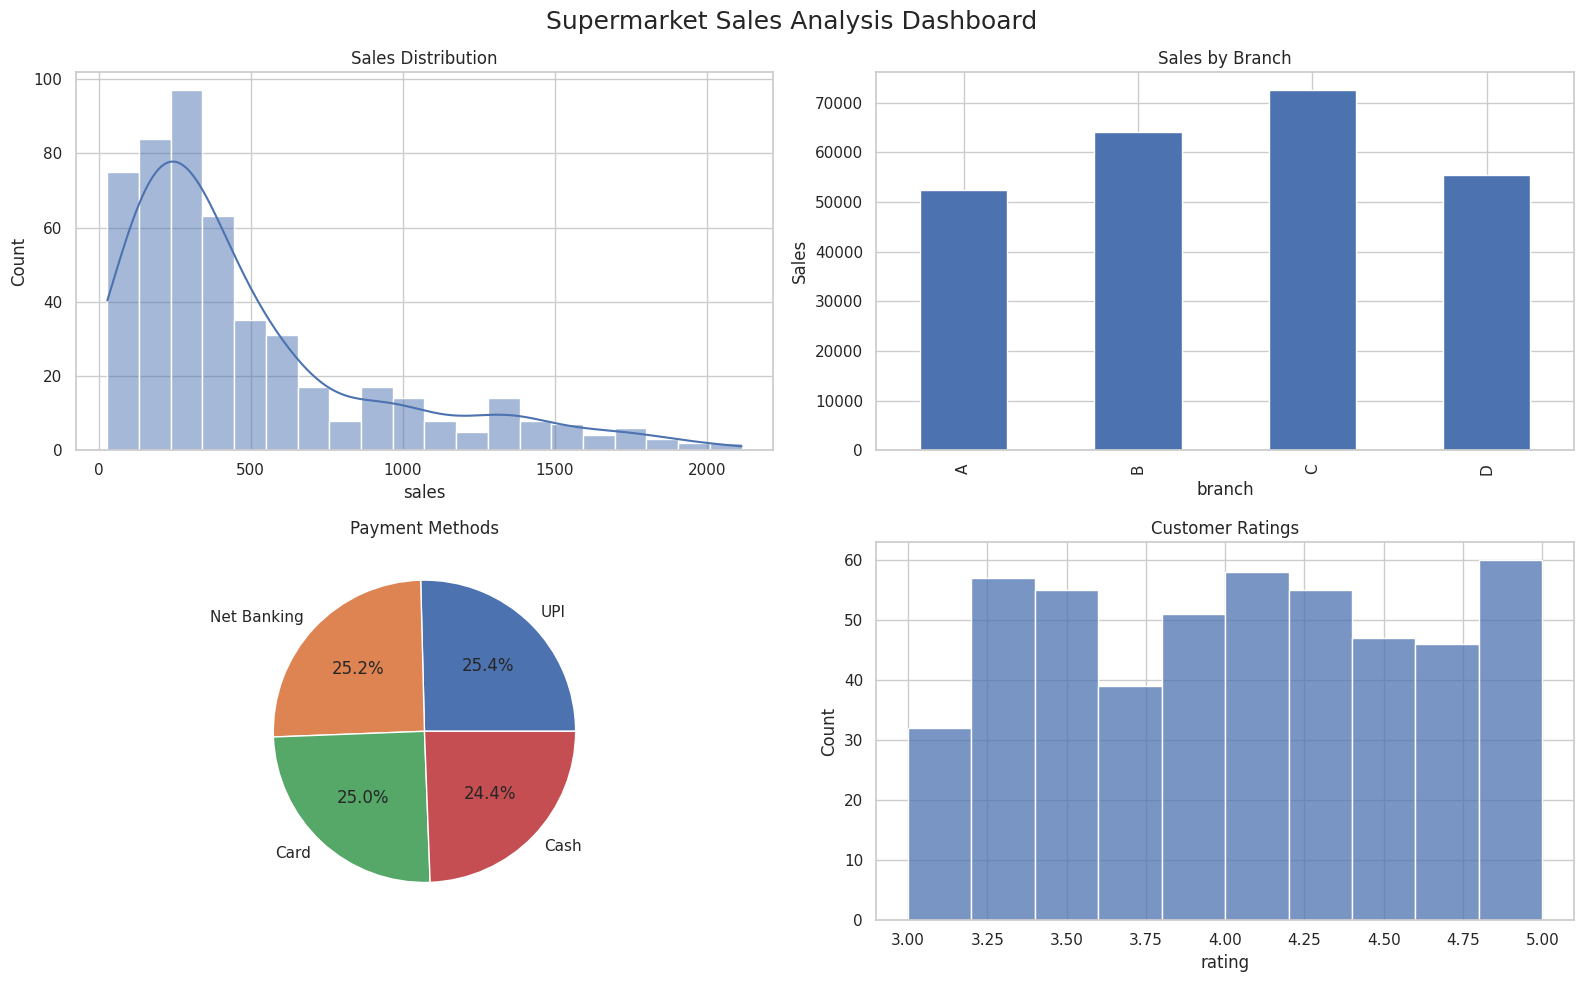

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Sales distribution
sns.histplot(
    df[sales_col].dropna(),
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Sales Distribution")

# 2. Branch sales
if branch_col is not None:
    df.groupby(branch_col)[sales_col].sum().plot(
        kind="bar",
        ax=axes[0, 1]
    )
    axes[0, 1].set_title("Sales by Branch")
    axes[0, 1].set_ylabel("Sales")
else:
    axes[0, 1].set_visible(False)

# 3. Payment method counts
if payment_col is not None:
    df[payment_col].value_counts().plot(
        kind="pie",
        autopct="%1.1f%%",
        ax=axes[1, 0]
    )
    axes[1, 0].set_title("Payment Methods")
    axes[1, 0].set_ylabel("")
else:
    axes[1, 0].set_visible(False)

# 4. Customer ratings
if rating_col is not None:
    sns.histplot(
        df[rating_col].dropna(),
        bins=10,
        ax=axes[1, 1]
    )
    axes[1, 1].set_title("Customer Ratings")
else:
    axes[1, 1].set_visible(False)

plt.suptitle(
    "Supermarket Sales Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [25]:
# Save the cleaned dataset
df.to_csv("cleaned_supermarket_sales.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [26]:
from google.colab import files

files.download("cleaned_supermarket_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
requirements = """pandas
numpy
matplotlib
seaborn
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [28]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
readme_content = """
# Supermarket Sales Analysis

## 1. Project Overview

This project analyzes supermarket sales data to identify sales
trends, product performance, branch performance, customer behavior,
payment preferences, and customer ratings.

## 2. Problem Statement

The objective is to transform supermarket transaction data into
meaningful business insights that can support better decision-making.

## 3. Objectives

- Analyze overall supermarket sales.
- Identify the highest-selling products.
- Compare sales across branches.
- Analyze product categories.
- Identify popular payment methods.
- Compare customer spending.
- Examine customer ratings.
- Visualize important findings.
- Recommend business improvements.

## 4. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## 5. Project Workflow

1. Load the dataset.
2. Explore the data.
3. Check missing values and duplicate records.
4. Prepare the sales data.
5. Perform exploratory data analysis.
6. Analyze products and branches.
7. Analyze customer types and payment methods.
8. Create visualizations.
9. Generate business insights.
10. Export the results.

## 6. Analysis Performed

- Overall sales analysis
- Product sales analysis
- Branch performance analysis
- Category analysis
- Payment method analysis
- Customer analysis
- Customer rating analysis
- Correlation analysis
- Sales dashboard

## 7. Business Benefits

The analysis can help supermarket management understand
product demand, compare branch performance, evaluate payment
preferences, and identify opportunities to improve customer
experience.

## 8. How to Run the Project

1. Open Google Colab.
2. Upload the project notebook.
3. Upload the supermarket sales CSV file when prompted.
4. Run the notebook cells in order.
5. Review the generated charts and results.

## 9. Project Deliverables

- Python Jupyter Notebook
- Requirements file
- Project report
- README documentation

## 10. Conclusion

This project demonstrates how Python-based data analytics can
turn supermarket transaction data into useful information for
business planning and decision-making.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [30]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.5 MB/s eta 0:00:00


In [32]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

# Create document
doc = Document()

# Set document margins
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Default font
style = doc.styles["Normal"]
style.font.name = "Arial"
style.font.size = Pt(11)

# Title
title = doc.add_heading(
    "SUPERMARKET SALES ANALYSIS",
    level=0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph("DATA ANALYTICS PROJECT")
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_paragraph("Prepared by: Harini")
doc.add_paragraph("Tools: Python, Pandas, NumPy, Matplotlib, Seaborn")
doc.add_paragraph("Platform: Google Colab")

# 1. Introduction
doc.add_heading("1. Introduction", level=1)

doc.add_paragraph(
    "Supermarket sales analysis uses transaction data to understand "
    "sales performance, product demand, branch performance, payment "
    "preferences, and customer behavior. Data analytics helps convert "
    "raw transaction records into meaningful information that supports "
    "business decision-making."
)

# 2. Problem Statement
doc.add_heading("2. Problem Statement", level=1)

doc.add_paragraph(
    "The aim of this project is to analyze supermarket sales data and "
    "identify useful information about products, branches, categories, "
    "customers, payment methods, and customer ratings."
)

# 3. Objectives
doc.add_heading("3. Project Objectives", level=1)

objectives = [
    "Examine and understand the supermarket dataset.",
    "Identify missing values and duplicate records.",
    "Calculate and summarize sales.",
    "Identify products generating the highest sales.",
    "Compare sales performance across branches.",
    "Analyze product categories and payment methods.",
    "Compare sales across customer types.",
    "Examine customer ratings.",
    "Create visualizations and suggest business improvements."
]

for objective in objectives:
    doc.add_paragraph(objective, style="List Bullet")

# 4. Dataset
doc.add_heading("4. Dataset Description", level=1)

doc.add_paragraph(
    "The project brief describes a dataset containing 500 sales "
    "transactions. The listed information includes products, branches, "
    "cities, customer types, quantities, prices, payment methods, "
    "ratings, and sales. The exact dataset structure should be verified "
    "against the CSV file used for the analysis."
)

# 5. Tools
doc.add_heading("5. Tools and Technologies", level=1)

tools_used = [
    "Python: Programming and analysis.",
    "Pandas: Data manipulation and analysis.",
    "NumPy: Numerical operations.",
    "Matplotlib: Data visualization.",
    "Seaborn: Statistical visualization.",
    "Google Colab: Cloud-based coding environment."
]

for item in tools_used:
    doc.add_paragraph(item, style="List Bullet")

# 6. Methodology
doc.add_heading("6. Methodology", level=1)

steps = [
    "Load the CSV dataset into Python.",
    "Inspect rows, columns, and data types.",
    "Check missing values and duplicate records.",
    "Prepare the sales data for analysis.",
    "Calculate summary statistics.",
    "Analyze products, branches, and categories.",
    "Analyze payment methods and customer types.",
    "Visualize the findings.",
    "Develop business recommendations."
]

for step in steps:
    doc.add_paragraph(step, style="List Number")

# 7. Analysis
doc.add_heading("7. Exploratory Data Analysis", level=1)

doc.add_paragraph(
    "The analysis examines overall sales, average transaction value, "
    "product performance, branch performance, category performance, "
    "payment preferences, customer spending, and customer ratings. "
    "Charts are used to make patterns easier to understand."
)

# 8. Results
doc.add_heading("8. Results and Findings", level=1)

doc.add_paragraph(
    "Insert the actual results from the completed Python notebook here. "
    "Include total sales, average sales per record, top-selling product, "
    "best-performing branch, leading category, most frequently used "
    "payment method, and average customer rating where those fields "
    "are available."
)

# 9. Business Recommendations
doc.add_heading("9. Business Recommendations", level=1)

recommendations = [
    "Use sales trends to support inventory planning.",
    "Study the reasons behind differences in branch performance.",
    "Monitor customer payment preferences.",
    "Use customer feedback to identify service improvements.",
    "Design promotions based on observed purchasing patterns.",
    "Review sales and customer metrics regularly."
]

for recommendation in recommendations:
    doc.add_paragraph(recommendation, style="List Bullet")

# 10. Limitations
doc.add_heading("10. Limitations", level=1)

doc.add_paragraph(
    "The findings depend on the quality, completeness, and size of the "
    "available dataset. Sales totals do not necessarily represent profit. "
    "The analysis also cannot establish causal relationships from "
    "correlation alone."
)

# 11. Conclusion
doc.add_heading("11. Conclusion", level=1)

doc.add_paragraph(
    "This project demonstrates how Python-based data analytics can "
    "transform supermarket transaction records into useful business "
    "insights. The results can support better understanding of sales, "
    "products, branches, customer preferences, and opportunities for "
    "improvement."
)

# Save report
report_path = "/content/Harini_ProjectReport.docx"
doc.save(report_path)

print("Project report created successfully!")

Project report created successfully!


In [35]:
from google.colab import files

files.download("/content/Harini_ProjectReport.docx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import os
import zipfile

from google.colab import files

project_dir = "/content/supermarket_project"
os.makedirs(project_dir, exist_ok=True)

required_files = [
    "/content/Harini_SupermarketSalesAnalysis.ipynb",
    "/content/requirements.txt",
    "/content/supermarket_project/Harini_ProjectReport.docx",
    "/content/README.md"
]

# Verify every required file exists.
missing_files = [
    path for path in required_files
    if not os.path.exists(path)
]

if missing_files:
    print("The following files are missing:")
    for path in missing_files:
        print("-", path)

    print(
        "\nCreate or upload the missing files before "
        "generating the final ZIP."
    )

else:
    zip_path = "/content/Harini_SupermarketSalesAnalysis_Project.zip"

    with zipfile.ZipFile(
        zip_path, "w", zipfile.ZIP_DEFLATED
    ) as zip_file:

        for path in required_files:
            zip_file.write(
                path,
                arcname=os.path.basename(path)
            )

    print("Final project ZIP created successfully!")
    files.download(zip_path)

The following files are missing:
- /content/Harini_SupermarketSalesAnalysis.ipynb
- /content/supermarket_project/Harini_ProjectReport.docx

Create or upload the missing files before generating the final ZIP.
